# NLPCC2017 新闻标题生成：T5 文本摘要微调

## 实验目标

以 NLPCC2017 中文新闻数据集为对象，用中文 T5（`Langboat/mengzi-t5-base`）完成生成式文本摘要（新闻标题生成）的微调实战，跑通从数据到模型的完整流程：

1. 数据分析：读取与体检、去重、训练/评估划分；
2. 生成式建模：把「长正文 → 短标题」形式化为 Seq2Seq 任务，理解 `input_ids` / `attention_mask` / `labels` 的编码设计与交叉熵训练目标；
3. 微调实验：在 6GB 显存下完成 T5 全参数微调（bf16 + Adafactor + 梯度检查点），用 ROUGE 评估并做生成样例分析；
4. 留一组全参微调的对照基线，为下一课的 LoRA 参数高效微调实验作对比。

## 任务与数据

- 数据：`nlpcc_2017/nlpcc_data.json`，共 50000 条，字段为 `content`（新闻正文，长文本）与 `title`（新闻标题，短文本）；
- 任务：给定正文生成标题，即单文档摘要——输入长序列、输出短序列：

$$
(x_1,\ldots,x_S) \longrightarrow (y_1,\ldots,y_T),\qquad T \ll S
$$

- 与上一课（ChnSentiCorp 情感分类）的区别：分类是「一段话 → 一个类别」，本实验是「一段话 → 一段话」，模型在原文条件下逐 Token 生成新的短序列。

## 实验设计

- 模型：`Langboat/mengzi-t5-base`（247.6M 参数的中文 Encoder-Decoder T5，全参数微调）；
- 训练：训练集 5000 条 / 评估集 1000 条（先以子集跑通流程），3 个 Epoch，等效 Batch Size 16；
- 评估：ROUGE-1 / ROUGE-2 / ROUGE-L（按字符切分），外加生成样例的人工分析；
- 环境：RTX 3060 Laptop（6GB 显存）· Python 3.11 · PyTorch 2.10 · Transformers 5.16。

## 笔记本结构

| 单元格 | 内容 |
|---|---|
| 2~7 | 数据读取与体检 → 长度统计 → 去重 → 训练/评估划分 |
| 8~14 | T5 微调全流程：加载模型 → 分词编码 → DataCollator → ROUGE → 训练参数 → Trainer → 训练 |
| 15~16 | 评估/保存最优模型 → 生成演示 |
| 17 | 实验总结与分析 |

In [1]:
import json
from pathlib import Path

# NLPCC2017 新闻数据集:整体是一个 JSON 对象 {"version": ..., "data": [...]}
# 每条记录含 title(新闻标题) / content(新闻正文)
DATA_PATH = Path("nlpcc_2017/nlpcc_data.json")

with open(DATA_PATH, encoding="utf-8") as f:
    raw = json.load(f)

print("顶层字段:", list(raw.keys()))
print("version:", raw["version"])

records = raw["data"]
print("记录条数:", len(records))
print("单条记录字段:", list(records[0].keys()))
print()
print("第1条 title:", records[0]["title"])
print("第1条 content(前100字):", records[0]["content"][:100])

顶层字段: ['version', 'data']
version: 0.0.1
记录条数: 50000
单条记录字段: ['title', 'content']

第1条 title: 知情人透露章子怡怀孕后,父母很高兴。章母已开始悉心照料。据悉,预产期大概是12月底
第1条 content(前100字): 四海网讯,近日,有媒体报道称:章子怡真怀孕了!报道还援引知情人士消息称,“章子怡怀孕大概四五个月,预产期是年底前后,现在已经不接工作了。”这到底是怎么回事?消息是真是假?针对此消息,23日晚8时30分


In [2]:
import pandas as pd

# 转成 DataFrame 方便统计
df = pd.DataFrame(records)
print("数据形状:", df.shape)
print()
print("缺失值统计:")
print(df.isnull().sum())
print("空字符串:", (df["title"].str.strip() == "").sum(),
      "条 title /", (df["content"].str.strip() == "").sum(), "条 content")
print("完全重复记录:", df.duplicated().sum(), "条 (去重后剩", len(df.drop_duplicates()), "条)")
print("title 重复:", df["title"].duplicated().sum(), "条")
# 数据质量: 正文不含任何空白字符(已清洗过); 部分标题含原始空格(如"大火烈鸟 尚不清楚具体来源")
print("title 含空格的比例: {:.1%}".format(df["title"].str.contains(" ").mean()))

数据形状: (50000, 2)

缺失值统计:
title      0
content    0
dtype: int64
空字符串: 0 条 title / 0 条 content
完全重复记录: 6271 条 (去重后剩 43729 条)
title 重复: 6374 条
title 含空格的比例: 10.2%


标题长度(字符):
count    50000.0
mean        44.6
std          9.7
min         17.0
25%         40.0
50%         46.0
75%         50.0
max        128.0
Name: title_len, dtype: float64

正文长度(字符):
count    50000.0
mean       990.0
std       1049.6
min         52.0
25%        368.0
50%        684.0
75%       1242.0
max      22312.0
Name: content_len, dtype: float64

正文长度分位: {'P50': 684, 'P90': 2102, 'P95': 2781, 'P99': 4998, 'P100': 22312}
正文超过 512 字比例: 62.8% (BERT系输入上限512,生成任务需考虑截断)


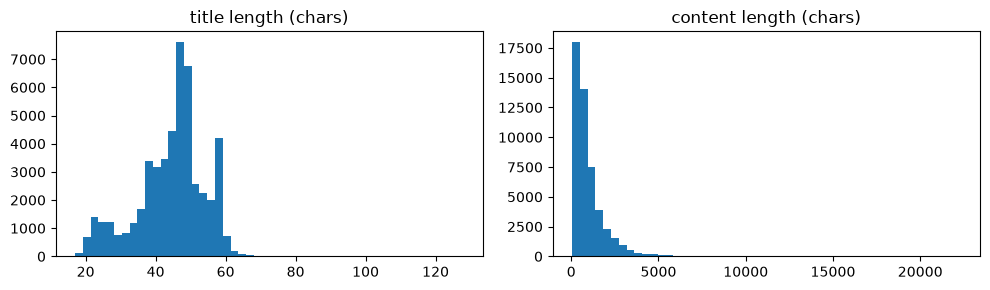

In [3]:
import matplotlib.pyplot as plt

# 字符数(不是 token 数;中文按字统计,做 max_length 截断时的参考)
df["title_len"] = df["title"].str.len()
df["content_len"] = df["content"].str.len()

print("标题长度(字符):")
print(df["title_len"].describe().round(1))
print()
print("正文长度(字符):")
print(df["content_len"].describe().round(1))
print()
print("正文长度分位:", {f"P{int(q*100)}": int(df["content_len"].quantile(q))
                    for q in (0.5, 0.9, 0.95, 0.99, 1.0)})
print("正文超过 512 字比例: {:.1%} (BERT系输入上限512,生成任务需考虑截断)".format(
    (df["content_len"] > 512).mean()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(df["title_len"], bins=50)
axes[0].set_title("title length (chars)")
axes[1].hist(df["content_len"], bins=50)
axes[1].set_title("content length (chars)")
fig.tight_layout()
plt.show()

In [5]:
# 随机抽 3 条看看(固定种子 42,可复现)
for i, row in df.sample(3, random_state=42).iterrows():
    print(f"—— 第 {i} 条 ——")
    print("标题:", row["title"])
    print("正文:", row["content"][:180], "……")
    print()

—— 第 33553 条 ——
标题: 国航紧急抽调一架空客A319客机空舱飞赴加德满都,将我国滞留旅客运回。
正文: 民航资源网2015年4月26日消息:为尽快将加德满都滞留旅客运回,国航紧急抽调一架空客A319客机,以客舱空舱状态,于22:58从成都双流机场飞往加德满都机场。预计该机于北京时间26日凌晨01:47抵达。这是国内第一架飞往加德满都执行滞留旅客疏散任务的航班。26日清晨6点,国航总部将派出一架空客A330执行救灾运输任务,航班号为CA058,从北京直飞加德满都 ……

—— 第 9427 条 ——
标题: 张务锋被任命为山东省副省长,其山东发改委主任职务被免,由王忠林接任
正文: 7月24日上午,山东省十二届人大常委会第十五次会议在济南闭会。图为会议现场。山东省人大接受于晓明辞去副省长职务请求大众网济南7月24日讯(记者于潇潇)7月24日上午,山东省十二届人大常委会第十五次会议在济南闭会。会议表决通过了关于接受于晓明辞去山东省副省长职务的请求的决定。据了解,此前因工作变动,于晓明请求辞去山东省副省长职务。此前,中共中央批准于晓明任山东 ……

—— 第 199 条 ——
标题: 银川:女子阻挠民警执法,被审讯时要求用美图拍照,称这样会让她更加漂亮。
正文: 新消息报2014-10-2709:59显示图片本报讯(记者张磊)银川一男子车上装有刀具,民警发现后准备对其审查时,遭到该男子一名女性朋友阻拦。女子不仅将民警的执法仪器抢走,还用脚猛踹警车门。更让人无语的是,该女子被带回派出所审讯室时,竟提出让民警用“美图秀秀”软件来拍照,这样会让她更加漂亮。10月25日凌晨,西夏区公安分局巡防一大队接到报案称,西夏区801工 ……



In [7]:
# 去重:title+content 完全相同的记录只保留第一条
# 注意:必须"先去重、再划分",否则相同样本可能同时落入 train/test,造成数据泄漏
df_dedup = df.drop_duplicates(subset=["title", "content"]).reset_index(drop=True)
print("去重前:", len(df), "条 → 去重后:", len(df_dedup), "条 (删除", len(df) - len(df_dedup), "条)")
# 剩余的同标题记录(标题相同但正文不同,多为转载/改写,保留)
print("剩余重复标题:", df_dedup["title"].duplicated().sum(), "条")

去重前: 50000 条 → 去重后: 43729 条 (删除 6271 条)
剩余重复标题: 103 条


In [8]:
from datasets import Dataset

# 只保留建模用的两列,转成 HuggingFace datasets.Dataset(方便后续 map/tokenize)
ds = Dataset.from_pandas(df_dedup[["title", "content"]], preserve_index=False)
# 划分 train/test = 8:2,固定种子 42 保证可复现(同昨天 ChnSentiCorp 的划分习惯)
data = ds.train_test_split(test_size=0.2, seed=42)
print("train:", len(data["train"]), "条 / test:", len(data["test"]), "条")
data

d:\project\step3\llm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 34983 条 / test: 8746 条


DatasetDict({
    train: Dataset({
        features: ['title', 'content'],
        num_rows: 34983
    })
    test: Dataset({
        features: ['title', 'content'],
        num_rows: 8746
    })
})

In [9]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# ===== 阶段二:T5 文本摘要(正文→标题) =====
# 中文 T5(孟子 mengzi-t5-base):encoder-decoder 结构,天生适合"输入文本→输出文本"
# 权重已提前下载到本地缓存,加载会很快
MODEL_NAME = "Langboat/mengzi-t5-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

print(type(model).__name__)
print("可训练参数量: %.1fM" % (sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6))

Loading weights: 100%|██████████| 282/282 [00:00<00:00, 5809.86it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


T5ForConditionalGeneration
可训练参数量: 247.6M


In [10]:
MAX_INPUT_LENGTH = 512   # 正文输入上限(超出截断);正文中位数 684 字,超出的取前半段
MAX_TARGET_LENGTH = 64   # 标题输出上限(约覆盖 96% 样本,实测最长 128)

def process_function(examples):
    # 输入:正文 -> input_ids / attention_mask
    inputs = tokenizer(examples["content"], max_length=MAX_INPUT_LENGTH, truncation=True)
    # 目标:标题 -> labels(生成任务的监督信号)
    labels = tokenizer(examples["title"], max_length=MAX_TARGET_LENGTH, truncation=True)
    inputs["labels"] = labels["input_ids"]
    return inputs

# 批量编码;pandas 原始文本列编码后不再需要,直接删掉
tokenized_data = data.map(process_function, batched=True, remove_columns=data["train"].column_names)

# 抽查一条:看编码长度是否符合预期
example = tokenized_data["train"][0]
print("input_ids 长度:", len(example["input_ids"]), "| labels 长度:", len(example["labels"]))
tokenized_data

Map: 100%|██████████| 8746/8746 [00:03<00:00, 2330.68 examples/s]

input_ids 长度: 163 | labels 长度: 39


DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 34983
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 8746
    })
})

In [11]:
from transformers import DataCollatorForSeq2Seq

# 动态 padding:输入补 pad token 到 batch 内最长;
# 标签补 -100(损失计算会忽略 -100,不会把 padding 当答案学)
collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model, label_pad_token_id=-100)

In [12]:
import numpy as np
import evaluate

# ROUGE:摘要任务的标配指标(1/2 为字级一元、二元重叠,L 为最长公共子序列)
rouge = evaluate.load("rouge")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    # 生成结果和标签里的 -100 先还原成 pad id,再解码成文本
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    # 中文没有空格,必须按"字符"切分,否则整句会被当成一个词
    result = rouge.compute(predictions=decoded_preds, references=decoded_labels,
                           tokenizer=lambda x: list(x))
    return {k: round(v, 4) for k, v in result.items()}

In [18]:
from transformers import Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir="./results_t5",          # T5 的 checkpoint 目录(与 rbt3 的 ./results 区分)
    num_train_epochs=3,                 # 训练轮数(只想快速跑通可改成 1,约 45 分钟)
    per_device_train_batch_size=8,      # 6G 显存下的安全批量(冒烟实测峰值约 3.6GB)
    gradient_accumulation_steps=2,      # 梯度累积 2 步 → 等效批量 16
    per_device_eval_batch_size=16,
    learning_rate=2e-5,                 # 微调学习率
    warmup_steps=200,                   # 学习率预热(transformers 5 已没有 warmup_ratio)
    weight_decay=0.01,
    logging_steps=100,
    optim="adafactor",                  # 省显存优化器:6G 卡装不下 AdamW(优化器状态就要约 4GB),会溢出到共享内存导致训练极慢
    gradient_checkpointing=True,        # 梯度检查点:用重算换显存,小显存跑 T5 的标配
    eval_strategy="epoch",              # 每轮结束评估(生成 + 算 ROUGE)
    save_strategy="epoch",
    save_total_limit=2,                 # 只留最近 2 个 checkpoint,省磁盘
    bf16=True,                          # 30 系显卡支持 bf16;T5 对 fp16 容易溢出,bf16 更稳
    predict_with_generate=True,         # 评估时真实生成标题再算 ROUGE(生成任务必须)
    generation_max_length=64,
    load_best_model_at_end=True,        # 训练结束自动载入最优 checkpoint
    metric_for_best_model="rougeL",     # 以 rougeL 判定"最优"
    report_to="none",
)

In [19]:
from transformers import Seq2SeqTrainer

TRAIN_SIZE = 5000   
EVAL_SIZE = 1000    

train_subset = tokenized_data["train"].shuffle(seed=42).select(range(TRAIN_SIZE))
eval_subset = tokenized_data["test"].select(range(EVAL_SIZE))
print("训练集:", len(train_subset), "条 | 评估集:", len(eval_subset), "条")

# 组装 Seq2SeqTrainer:模型、参数、数据集、数据整理器、评估函数
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_subset,
    eval_dataset=eval_subset,
    data_collator=collator,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,   # transformers 5 的参数名(旧版叫 tokenizer)
)

训练集: 5000 条 | 评估集: 1000 条


In [ ]:
# 正式训练:5000 条 × 3 轮,实测 1 小时 11 分(约 0.29 秒/样本)
# 结果:第 2 轮最优(rougeL 0.3688),训练结束已自动载入最优模型,无需重跑此格
# 训练日志在下方滚动;中途点停止没关系,已保存的 checkpoint 可以接着用
trainer.train()

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,6.488613,2.805223,0.377600,0.232000,0.328400,0.328700
2,5.638706,2.638689,0.422300,0.267300,0.368800,0.368900
3,5.241300,2.612125,0.422300,0.269500,0.366300,0.366300


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.35it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


TrainOutput(global_step=939, training_loss=6.427358300287248, metrics={'train_runtime': 4277.2516, 'train_samples_per_second': 3.507, 'train_steps_per_second': 0.22, 'total_flos': 1.0256638003642368e+16, 'train_loss': 6.427358300287248, 'epoch': 3.0})

In [16]:
# 训练完成后运行:在评估子集(1000 条)上评估并保存最优模型
# 想看全量 test(8746 条)可改成:metrics = trainer.evaluate(tokenized_data["test"])
metrics = trainer.evaluate()
print(metrics)

# 保存最优模型(load_best_model_at_end 已把最优权重载入 model)
model.save_pretrained("./t5_summary_best")
tokenizer.save_pretrained("./t5_summary_best")

Training Loss,Validation Loss,Epoch,Rouge1,Rouge2,Rougel,Rougelsum
5.241300,2.638689,3,0.422300,0.267300,0.368800,0.368900


{'eval_loss': 2.6386892795562744, 'eval_rouge1': 0.4223, 'eval_rouge2': 0.2673, 'eval_rougeL': 0.3688, 'eval_rougeLsum': 0.3689}


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.64s/it]


('./t5_summary_best\\tokenizer_config.json',
 './t5_summary_best\\tokenizer.json')

In [17]:
# 训练完成后运行:抽 3 条 test 样本生成标题,与参考标题对比
# (训练前运行会输出乱码,属正常现象;beam=4 即每次保留 4 条候选选最优)
samples = data["test"].select(range(3))
for i in range(len(samples)):
    text = samples[i]["content"]
    inputs = tokenizer(text, return_tensors="pt", max_length=512, truncation=True).to(model.device)
    generated = model.generate(**inputs, max_new_tokens=64, num_beams=4)
    print(f"—— 样本 {i} ——")
    print("参考标题:", samples[i]["title"])
    print("生成标题:", tokenizer.decode(generated[0], skip_special_tokens=True))
    print()

[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


—— 样本 0 ——
参考标题: 福州:4起“公车私用”人员被纪委查处。包括鼓楼区信访局长公车参加私人聚会,环保局环境监察大队长接送其妻子等。
生成标题: 福州4起违反公车使用管理规定“公车私用”行为,被纪委立案调查。



[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


—— 样本 1 ——
参考标题: 衢州:江郎山景区停车场现一男一女两尸体,车内有农药瓶,经调查该车已停放两天以上,车门完好被反锁
生成标题: 衢州江郎山景区一轿车内惊现一男一女两名死者,车内有农药瓶,车内有浓重农药味,车内有浓重农药味。

—— 样本 2 ——
参考标题: 美媒称俄军给参赛解放军使坏:中国各种武器装备让俄方刮目相看,一旦中国要赢,俄方就试图修改规则
生成标题: 美媒称中国军队前所未有携带武器装备和弹药参加俄罗斯举行的国际军事比赛。



# 实验总结与分析

## 1. 实验目标与完整流程

本实验以 NLPCC2017 新闻数据集为基础，将新闻正文 `content` 作为输入长序列、新闻标题 `title` 作为目标短序列，使用 `Langboat/mengzi-t5-base` 完成生成式文本摘要任务。其本质是一个 Seq2Seq 任务：

$$
(x_1,x_2,\ldots,x_S) \longrightarrow (y_1,y_2,\ldots,y_T),\qquad T \ll S
$$

完整流程为：数据读取与检查 → 去重 → 训练集/评估集划分 → 正文与标题分别编码 → `DataCollatorForSeq2Seq` 动态补齐 → T5 全参数微调 → ROUGE 评估 → 生成标题并进行人工分析。

## 2. 数据处理分析

- 原始数据共 50000 条，字段为 `title` 和 `content`，没有缺失值或空字符串。
- 检测到 6271 条标题和正文完全相同的重复记录。先去重、再划分数据集，避免相同新闻同时进入训练集和评估集造成数据泄漏；去重后剩余 43729 条。
- 按 8:2、随机种子 42 划分后，训练集为 34983 条，测试划分为 8746 条。其中前 1000 条（`EVAL_SIZE=1000`）作为每轮评估与选模的评估子集，最终 ROUGE 也在这 1000 条上统计。由于该测试划分后续参与每轮评估和最佳 checkpoint 选择，严格来说它在本实验中承担的是验证集角色。
- 标题平均约 44.6 个字符，正文平均约 990 个字符；62.8% 的正文超过 512 个字符。当前输入最多保留 512 Token，因此较长新闻会被截断，位于正文后半部分的关键信息可能无法进入模型。字符长度与 Token 长度并不完全相同，后续可进一步统计分词后的真实截断比例。

## 3. 模型输入、输出与训练目标

孟子 T5 是 Encoder-Decoder 模型：Encoder 读取新闻正文，Decoder 在正文语义表示和已生成摘要 Token 的条件下逐步预测下一个 Token。主要张量形状可表示为：

- `input_ids`：$[B,S]$，正文 Token 序列；
- `attention_mask`：$[B,S]$，屏蔽正文中的 Padding；
- `labels`：$[B,T]$，目标标题 Token 序列；
- `logits`：$[B,T,V]$，每个输出位置在整个词表上的预测分数。

训练目标是最小化目标标题各有效 Token 的交叉熵：

$$
\mathcal{L}=-\frac{1}{N}\sum_{b,t}\log P(y_{b,t}\mid x_b,y_{b,<t})
$$

`DataCollatorForSeq2Seq` 对输入和标签进行动态 Padding，并将标签补齐位置设为 `-100`，使交叉熵忽略这些位置，不把 Padding 当成正确摘要学习。

## 4. 训练配置与结果

本次从全部数据中抽取 5000 条训练样本和 1000 条评估样本进行流程验证，训练 3 个 Epoch。单卡 Batch Size 为 8，梯度累积 2 步，等效 Batch Size 为 16；使用 bf16 混合精度、Adafactor 优化器和梯度检查点降低 6GB 显存下的训练压力。模型共有约 247.6M 个可训练参数，本实验属于全参数微调。

| Epoch | Eval Loss | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---:|---:|---:|---:|---:|
| 1 | 2.8052 | 0.3776 | 0.2320 | 0.3284 |
| 2 | 2.6387 | 0.4223 | 0.2673 | **0.3688** |
| 3 | **2.6121** | 0.4223 | **0.2695** | 0.3663 |

训练共完成 939 个优化步骤，耗时约 4277 秒（71.3 分钟）；训练显存峰值约 3.65GB，平均约 0.29 秒/样本（15000 个样本 ÷ 4277 秒）。由于 `metric_for_best_model="rougeL"`，第 2 轮的 `checkpoint-626` 被选为最佳模型，并最终保存到 `./t5_summary_best`。第 3 轮虽然 Eval Loss 和 ROUGE-2 略有改善，但 ROUGE-L 轻微下降，说明继续降低损失不一定会同步改善所选生成指标。

最终最佳模型在 1000 条评估数据上的结果为：`ROUGE-1=0.4223`、`ROUGE-2=0.2673`、`ROUGE-L=0.3688`。注意本实验的 ROUGE 为**字符级**计算（中文没有空格，计算时用 `tokenizer=lambda x: list(x)` 逐字符切分），与论文中常见的词级 ROUGE 数值不完全可比。这些指标说明模型已学会从正文中提取并重组部分关键信息，但 ROUGE 主要衡量字符片段和序列重叠，不能单独证明摘要事实正确、信息完整或语言质量良好。

## 5. 生成样例分析

- 样本 0 正确保留了“福州、4 起、公车私用、纪委调查”等核心信息，表达简洁，说明模型具备基本的信息压缩与重组能力。
- 样本 1 正确识别了地点、车辆、死者和农药瓶等信息，但“车内有浓重农药味”重复出现，暴露出生成模型的重复问题。
- 样本 2 生成语句通顺，也保留了中国军队、武器装备和俄罗斯军事比赛等内容，但遗漏了参考标题中的“俄方试图修改规则”这一核心矛盾，属于关键信息覆盖不足。

因此，当前模型已经跑通“长正文 → 短标题”的 Seq2Seq 链路，但仍存在重复生成、重点遗漏和长文本截断等问题。

## 6. 实验边界与改进方向

1. **建立独立测试集**：将数据划分为 train/validation/test，用 validation 选择最佳模型，最后只在 test 上评估一次，避免把模型选择结果当成独立测试结果。
2. **扩大有效训练规模**：本次只使用 5000 条训练数据，适合验证流程，但不能代表 34983 条训练数据的最终效果。可在资源允许时扩大数据量，并记录训练时间与指标变化。
3. **改进长文本处理**：统计 Token 长度和真实截断率；可尝试新闻导语提取、分段摘要、滑动窗口或支持更长上下文的模型，减少正文后半部分信息丢失。
4. **抑制重复生成**：推理时可实验 `no_repeat_ngram_size`、`repetition_penalty`、Beam Size 和长度惩罚，但应通过统一验证集比较，而不是只看个别样例。
5. **增加事实一致性检查**：ROUGE 之外还应人工检查人物、地点、数字、否定关系和事件主体，必要时增加 BERTScore 或专门的事实一致性指标。
6. **完善效率记录**：除总训练时间外，可继续记录峰值显存、生成延迟、每秒生成 Token 数和不同输入长度下的性能，从而形成完整的训练与部署分析。

## 7. 实验结论

本实验完成了从数据分析、去重划分、Seq2Seq 编码、T5 全参数微调、ROUGE 评估到摘要生成的完整 Hugging Face 文本摘要流程。最佳模型来自第 2 个 Epoch，能够生成语义基本相关且较简洁的新闻标题，但在重复控制、重点覆盖、事实一致性和长文本信息利用方面仍有改进空间。本实验验证了文本摘要的核心本质：模型不是为整段文本输出一个类别，而是在原文条件下逐 Token 生成一个更短的新序列。